In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/credit_risk_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [2]:
print("===== DATASET INFORMATION =====")

print("\nTotal Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\n===== COLUMN NAMES =====")
print(df.columns.tolist())

print("\n===== DATA TYPES =====")
print(df.dtypes)

print("\n===== DATASET INFO =====")
df.info()

===== DATASET INFORMATION =====

Total Rows: 32581
Total Columns: 12

===== COLUMN NAMES =====
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

===== DATA TYPES =====
person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

===== DATASET INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null 

In [3]:
print("===== MISSING VALUES =====")
print(df.isnull().sum())

print("\n===== MISSING VALUE PERCENTAGE =====")
print((df.isnull().mean() * 100).round(2))

print("\n===== DUPLICATE ROWS =====")
print(df.duplicated().sum())

===== MISSING VALUES =====
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

===== MISSING VALUE PERCENTAGE =====
person_age                    0.00
person_income                 0.00
person_home_ownership         0.00
person_emp_length             2.75
loan_intent                   0.00
loan_grade                    0.00
loan_amnt                     0.00
loan_int_rate                 9.56
loan_status                   0.00
loan_percent_income           0.00
cb_person_default_on_file     0.00
cb_person_cred_hist_length    0.00
dtype: float64

===== DUPLICATE ROWS =====
165


In [4]:
print("===== TARGET DISTRIBUTION =====")

print(df["loan_status"].value_counts())

print("\nTarget Percentage:")
print((df["loan_status"].value_counts(normalize=True) * 100).round(2))

===== TARGET DISTRIBUTION =====
loan_status
0    25473
1     7108
Name: count, dtype: int64

Target Percentage:
loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64


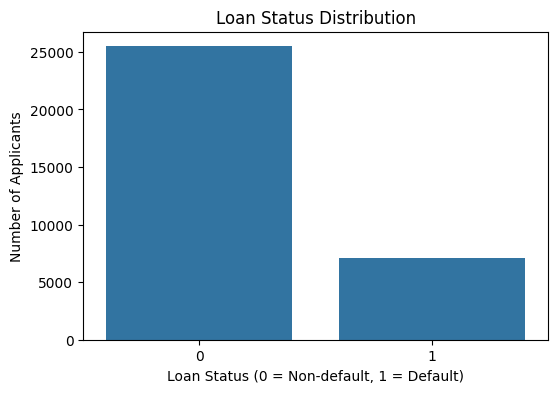

In [5]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="loan_status")

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Number of Applicants")

plt.show()

In [6]:
df.describe().round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


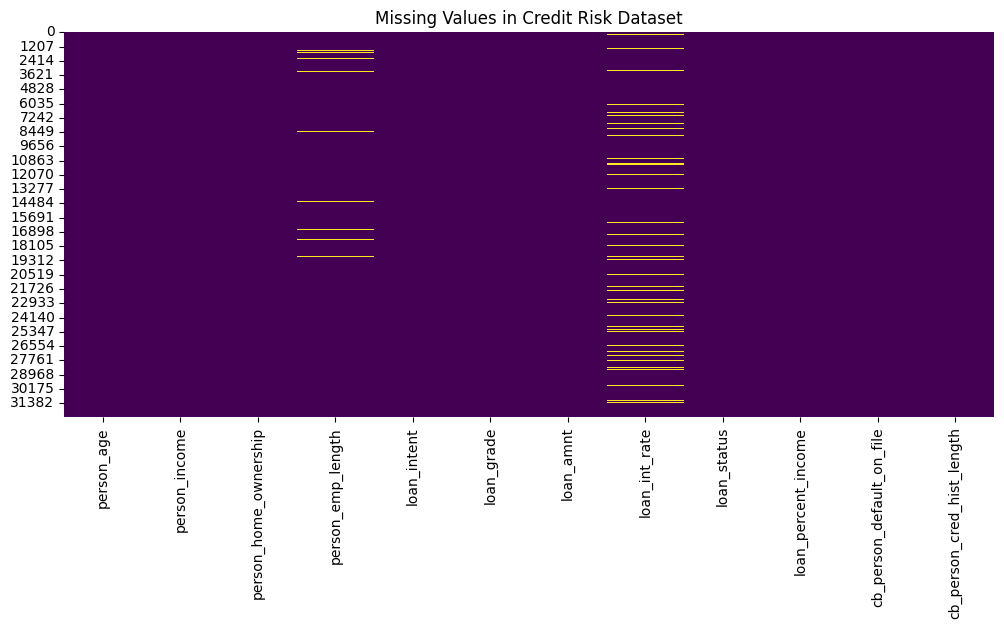

In [7]:
plt.figure(figsize=(12, 5))

sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Missing Values in Credit Risk Dataset")
plt.show()

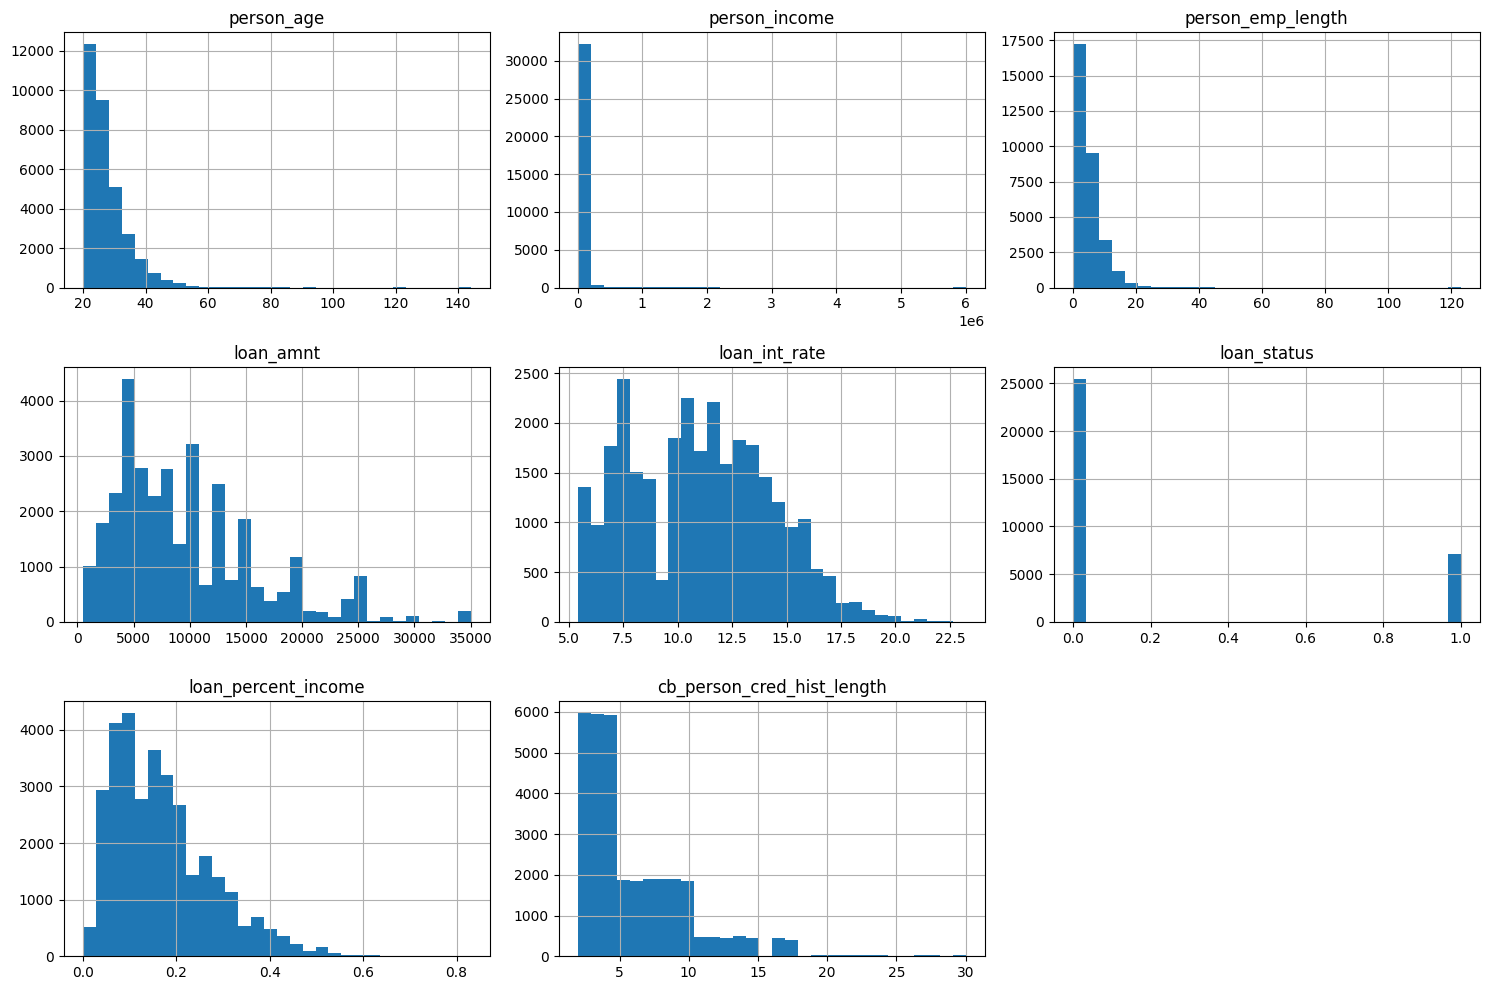

In [8]:
numerical_columns = df.select_dtypes(include=np.number).columns

df[numerical_columns].hist(figsize=(15, 10), bins=30)

plt.tight_layout()
plt.show()

In [9]:
# Find duplicate rows
duplicates = df[df.duplicated(keep=False)]

print("Total duplicate-related rows:", len(duplicates))

duplicates.head(10)

Total duplicate-related rows: 330


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
14,23,115000,RENT,2.0,EDUCATION,A,35000,7.90,0,0.30,N,4
238,22,183000,MORTGAGE,3.0,EDUCATION,A,1000,NaN,0,0.01,N,2
252,24,85000,RENT,5.0,MEDICAL,B,25000,10.62,0,0.29,N,4
591,26,20000,MORTGAGE,5.0,MEDICAL,A,4800,5.99,0,0.24,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
817,22,22000,OWN,1.0,DEBTCONSOLIDATION,D,8500,15.05,0,0.39,N,4
920,26,50000,RENT,10.0,PERSONAL,B,18950,NaN,1,0.38,N,3
1094,22,24449,OWN,2.0,VENTURE,B,1800,11.89,0,0.07,N,4
1142,25,60000,RENT,3.0,PERSONAL,A,17000,6.91,0,0.28,N,2
1453,23,20400,RENT,2.0,MEDICAL,A,1200,7.90,0,0.06,N,2


In [10]:
# Analyze rows containing missing values
missing_rows = df[df.isnull().any(axis=1)]

print("Rows containing missing values:", len(missing_rows))
print("\nMissing values by column:")
print(df.isnull().sum())

Rows containing missing values: 3943

Missing values by column:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


In [11]:
print("Employment length statistics:")
print(df["person_emp_length"].describe())

print("\nInterest rate statistics:")
print(df["loan_int_rate"].describe())

Employment length statistics:
count    31686.000000
mean         4.789686
std          4.142630
min          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
max        123.000000
Name: person_emp_length, dtype: float64

Interest rate statistics:
count    29465.000000
mean        11.011695
std          3.240459
min          5.420000
25%          7.900000
50%         10.990000
75%         13.470000
max         23.220000
Name: loan_int_rate, dtype: float64


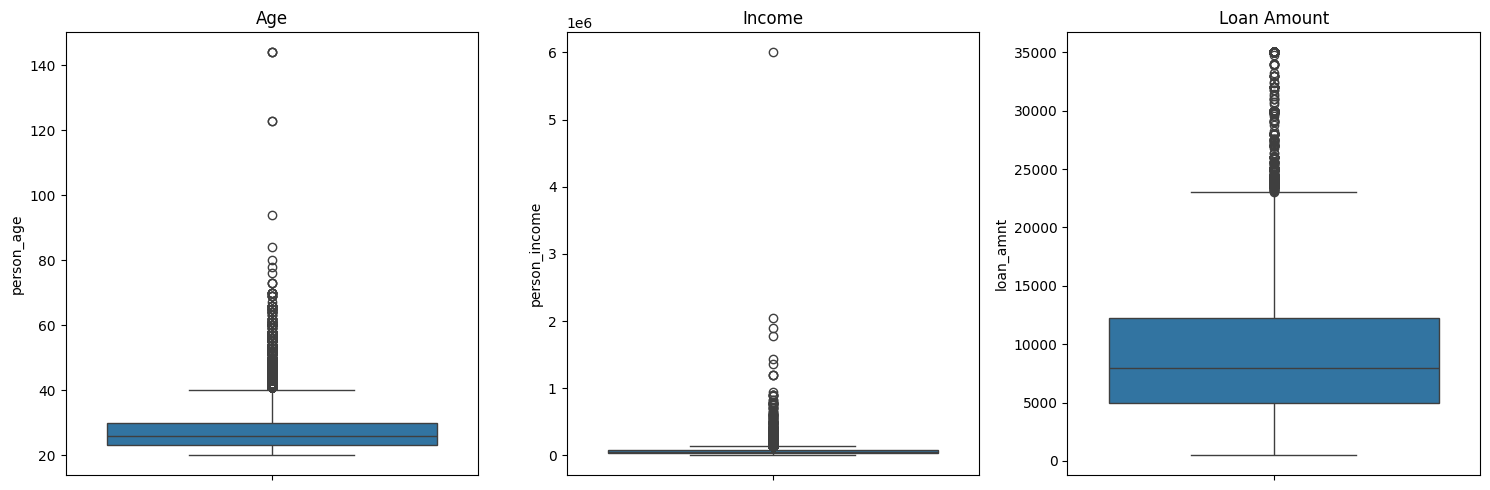

In [12]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.boxplot(y=df["person_age"])
plt.title("Age")

plt.subplot(1, 3, 2)
sns.boxplot(y=df["person_income"])
plt.title("Income")

plt.subplot(1, 3, 3)
sns.boxplot(y=df["loan_amnt"])
plt.title("Loan Amount")

plt.tight_layout()
plt.show()

In [13]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n===== {col} =====")
    print(df[col].value_counts())


===== person_home_ownership =====
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

===== loan_intent =====
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

===== loan_grade =====
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

===== cb_person_default_on_file =====
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


In [16]:
import os
import sys
import pandas as pd

# Add project root to Python path
PROJECT_ROOT = os.path.abspath("..")
sys.path.append(PROJECT_ROOT)

# Import preprocessing function
from src.preprocessing import prepare_data

# Load dataset
df = pd.read_csv("../data/credit_risk_dataset.csv")

print("Dataset loaded:", df.shape)

# Run preprocessing
X_train, X_test, y_train, y_test = prepare_data(df)

# Display results
print("\n===== PREPROCESSING RESULTS =====")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Dataset loaded: (32581, 12)

===== PREPROCESSING RESULTS =====
Training features: (25932, 26)
Testing features: (6484, 26)
Training target: (25932,)
Testing target: (6484,)


In [17]:

import os
import sys

sys.path.append(os.path.abspath(".."))

from src.models import train_logistic_regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train the baseline model
lr_model = train_logistic_regression(X_train, y_train)

# Predictions
y_pred = lr_model.predict(X_test)

# Probabilities for ROC-AUC
y_prob = lr_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("===== LOGISTIC REGRESSION BASELINE =====")

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred))

print("\n===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test, y_pred))


===== LOGISTIC REGRESSION BASELINE =====
Accuracy : 0.8691
Precision: 0.7728
Recall   : 0.5684
F1 Score : 0.655
ROC-AUC  : 0.868

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       0.89      0.95      0.92      5066
           1       0.77      0.57      0.66      1418

    accuracy                           0.87      6484
   macro avg       0.83      0.76      0.79      6484
weighted avg       0.86      0.87      0.86      6484


===== CONFUSION MATRIX =====
[[4829  237]
 [ 612  806]]


In [22]:
import os
import sys
import numpy as np
import torch

sys.path.append(os.path.abspath(".."))

from src.models import train_mlp
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Train model
mlp_model = train_mlp(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    learning_rate=0.001
)

# Predictions
mlp_model.eval()

with torch.no_grad():
    X_test_tensor = torch.tensor(
        X_test.toarray() if hasattr(X_test, "toarray") else X_test,
        dtype=torch.float32
    )

    logits = mlp_model(X_test_tensor)
    y_prob = torch.sigmoid(logits).numpy().flatten()
    y_pred = (y_prob >= 0.5).astype(int)

# Evaluation
print("\n===== MLP BASELINE =====")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

Epoch [1/20] - Loss: 0.3616
Epoch [2/20] - Loss: 0.2801
Epoch [3/20] - Loss: 0.2623
Epoch [4/20] - Loss: 0.2542
Epoch [5/20] - Loss: 0.2475
Epoch [6/20] - Loss: 0.2421
Epoch [7/20] - Loss: 0.2374
Epoch [8/20] - Loss: 0.2343
Epoch [9/20] - Loss: 0.2322
Epoch [10/20] - Loss: 0.2297
Epoch [11/20] - Loss: 0.2260
Epoch [12/20] - Loss: 0.2233
Epoch [13/20] - Loss: 0.2222
Epoch [14/20] - Loss: 0.2208
Epoch [15/20] - Loss: 0.2200
Epoch [16/20] - Loss: 0.2188
Epoch [17/20] - Loss: 0.2174
Epoch [18/20] - Loss: 0.2158
Epoch [19/20] - Loss: 0.2153
Epoch [20/20] - Loss: 0.2140

===== MLP BASELINE =====
Accuracy : 0.9212
Precision: 0.953
Recall   : 0.6728
F1 Score : 0.7888
ROC-AUC  : 0.9165


In [23]:
import pandas as pd
import os

baseline_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.8691,
        "Precision": 0.7728,
        "Recall": 0.5684,
        "F1": 0.6550,
        "ROC_AUC": 0.8680
    },
    {
        "Model": "MLP",
        "Accuracy": 0.9212,
        "Precision": 0.9530,
        "Recall": 0.6728,
        "F1": 0.7888,
        "ROC_AUC": 0.9165
    }
])

os.makedirs("../results", exist_ok=True)

baseline_results.to_csv(
    "../results/baseline_metrics.csv",
    index=False
)

baseline_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.8691,0.7728,0.5684,0.6550,0.8680
1,MLP,0.9212,0.9530,0.6728,0.7888,0.9165


In [24]:
import torch
import opacus

print("PyTorch:", torch.__version__)
print("Opacus:", opacus.__version__)

PyTorch: 2.14.1+cpu
Opacus: 1.6.0


In [ ]:
import os
import sys
import importlib

sys.path.append(os.path.abspath(".."))

import src.dp_training as dp_training

importlib.reload(dp_training)

print("DP training module loaded successfully.")
print("Function available:", hasattr(dp_training, "train_dp_mlp"))
print("Loaded from:", dp_training.__file__)